In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


In [2]:
files = [
    "paris-temp0-20261104-112810.csv",
    "rome-temp0-20261104-112810.csv",
    "spain-temp0-20261104-112810.csv"
]


df = pd.concat([pd.read_csv(file) for file in files], ignore_index=True)
display(df)


,dataset,strategy,trial,accuracy,duration_seconds,status
0,paris,FullHistory,1,85.71,25,success
1,paris,FullHistory,2,85.71,16,success
2,paris,FullHistory,3,85.71,12,success
3,paris,FullHistory,4,85.71,15,success
4,paris,FullHistory,5,85.71,13,success
5,paris,Summary,1,85.71,28,success
6,paris,Summary,2,85.71,28,success
7,paris,Summary,3,85.71,27,success
8,paris,Summary,4,85.71,30,success
9,paris,Summary,5,85.71,32,success


In [3]:
mean_accuracy = (
    df[df["status"] == "success"].groupby(["dataset", "strategy"])["accuracy"] .mean().unstack())

display(mean_accuracy.round(2))

strategy,FullHistory,Sisu,Summary
dataset,,,
paris,85.71,57.14,85.71
rome,85.71,57.14,85.71
spain,71.43,28.57,60.71


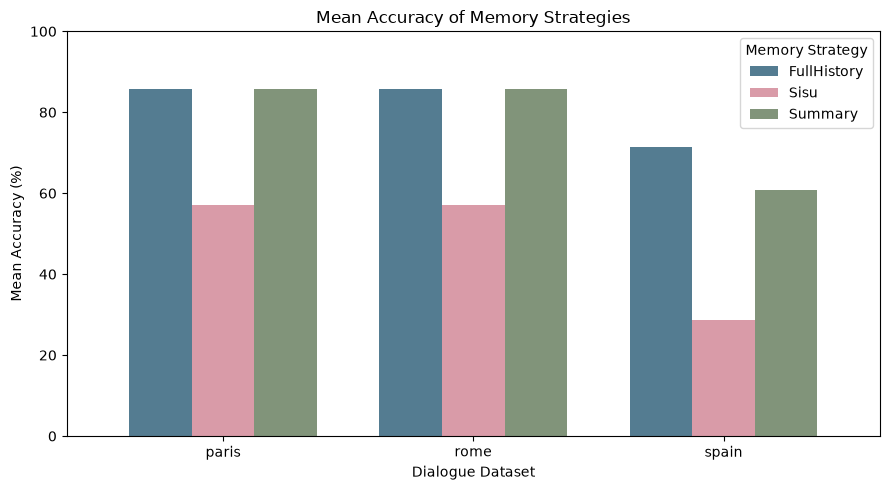

In [4]:
colors = ["#547C91", "#D99BA8", "#81947A"]
ax = mean_accuracy.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75,
    color=colors
)

plt.title("Mean Accuracy of Memory Strategies")
plt.xlabel("Dialogue Dataset")
plt.ylabel("Mean Accuracy (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Memory Strategy")
plt.tight_layout()

plt.savefig("mean_accuracy.png", dpi=300)
plt.show()

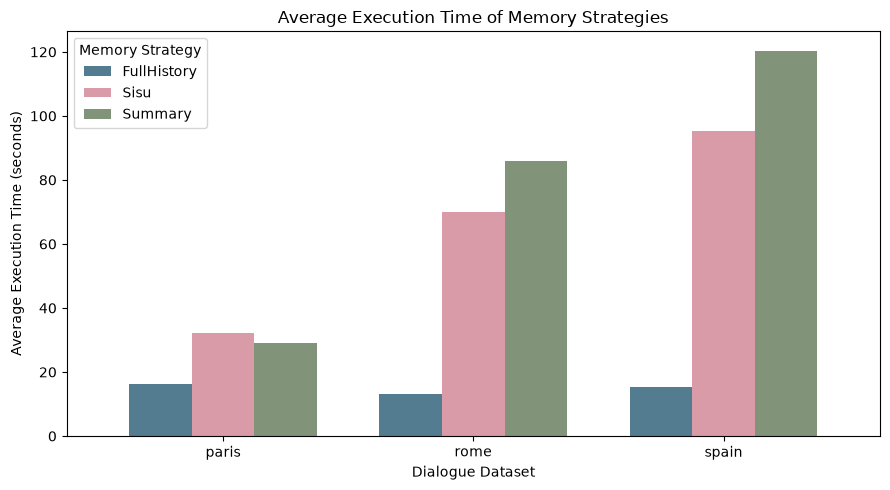

In [8]:
mean_time = (df.groupby(["dataset", "strategy"])["duration_seconds"] .mean().unstack())
colors = ["#547C91", "#D99BA8", "#81947A"]
ax = mean_time.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.75,
    color = colors
)

plt.title("Average Execution Time of Memory Strategies")
plt.xlabel("Dialogue Dataset")
plt.ylabel("Average Execution Time (seconds)")
plt.xticks(rotation=0)
plt.legend(title="Memory Strategy")
plt.tight_layout()

plt.savefig("mean_execution_time.png", dpi=300)
plt.show()

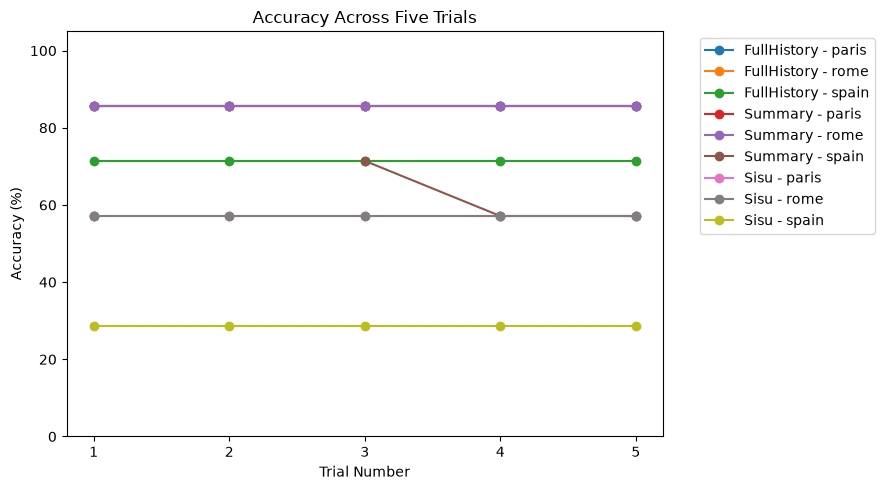

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

for strategy in ["FullHistory", "Summary", "Sisu"]:
    subset = df[df["strategy"] == strategy]

    for dataset in ["paris", "rome", "spain"]:
        data = subset[subset["dataset"] == dataset]

        ax.plot(
            data["trial"],
            data["accuracy"],
            marker="o",
            label=f"{strategy} - {dataset}"
        )

plt.title("Accuracy Across Five Trials")
plt.xlabel("Trial Number")
plt.ylabel("Accuracy (%)")
plt.xticks(range(1, 6))
plt.ylim(0, 105)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()

plt.savefig("accuracy_variation.png", dpi=300)
plt.show()

status,failed,success
strategy,,
FullHistory,0,15
Sisu,0,15
Summary,1,14


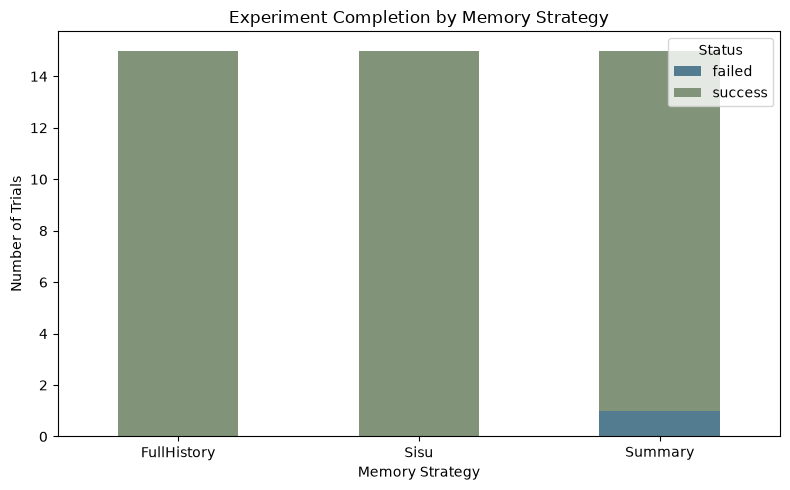

In [9]:
colors = ["#547C91", "#81947A"]
trial_status = (
    df.groupby(["strategy", "status"])
    .size()
    .unstack(fill_value=0)
)

display(trial_status)

trial_status.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color = colors
)

plt.title("Experiment Completion by Memory Strategy")
plt.xlabel("Memory Strategy")
plt.ylabel("Number of Trials")
plt.xticks(rotation=0)
plt.legend(title="Status")
plt.tight_layout()

plt.savefig("trial_completion.png", dpi=300)
plt.show()